# 02 · Pipeline y comparación de modelos (Producto 1)
**Métrica principal: exactitud balanceada** (promedio del recall de informales y del recall de formales). Con 78 % de informales, un modelo que dice "todos son informales" tendría un recall de informales de 1,00 sin aprender nada; la exactitud balanceada lo deja en 0,50. Reportamos también el **ROC-AUC** y los dos recalls por separado.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Datos: EPEN 2025 (INEI), departamento de Puno. El archivo está en data/ del repositorio.
NOMBRE = "21_Puno_EPEN_Anual_2025.csv"
RUTA = next((r for r in [f"../data/{NOMBRE}", f"data/{NOMBRE}", NOMBRE] if Path(r).exists()),
            "https://raw.githubusercontent.com/[USUARIO]/[REPOSITORIO]/main/data/" + NOMBRE)  # <- reemplazar

NUMERICAS = ["edad", "horas_semana", "ingreso_log", "n_limitaciones", "anios_estudio"]
CATEGORICAS = ["sexo", "area", "educacion", "lengua", "etnia", "ocupacion", "rama", "quiere_mas_horas"]

EDUC = {1: "Sin nivel/inicial", 2: "Sin nivel/inicial", 3: "Primaria incompleta", 4: "Primaria completa",
        5: "Secundaria incompleta", 6: "Secundaria completa", 7: "Sin nivel/inicial",
        8: "Superior no univ. incompleta", 9: "Superior no univ. completa",
        10: "Superior univ. incompleta", 11: "Superior univ. completa", 12: "Posgrado"}
ANIOS = {1: 0, 2: 0, 3: 3, 4: 6, 5: 8, 6: 11, 7: 0, 8: 12, 9: 14, 10: 13, 11: 16, 12: 18}  # años de estudio aprox.
OCUP = {0: "Fuerzas armadas", 1: "Directivos", 2: "Profesionales", 3: "Técnicos", 4: "Empleados de oficina",
        5: "Servicios y vendedores", 6: "Agricultores y pecuarios", 7: "Oficiales y artesanos",
        8: "Operadores de maquinaria", 9: "Ocupaciones elementales"}      # CIUO-08, gran grupo

def rama_ciiu(codigo):
    """Agrupa la división CIIU (4 dígitos, sin el cero inicial) en grandes ramas."""
    d = int(codigo) // 100
    if d <= 3:  return "Agricultura y pesca"
    if d <= 9:  return "Minería"
    if d <= 33: return "Manufactura"
    if d <= 39: return "Electricidad y agua"
    if d <= 43: return "Construcción"
    if d <= 47: return "Comercio"
    if d <= 53: return "Transporte"
    if d <= 56: return "Alojamiento y comidas"
    if d <= 82: return "Servicios a empresas"
    if d == 84: return "Administración pública"
    if d == 85: return "Educación"
    if d <= 88: return "Salud"
    return "Otros servicios y hogares"

def cargar_datos():
    raw = pd.read_csv(RUTA)
    # Población de estudio: personas OCUPADAS (OCUP300 = 1) con el indicador de informalidad del INEI
    d = raw[(raw["OCUP300"] == 1) & raw["Informal_P"].notna()].copy()
    out = pd.DataFrame({
        "edad": d["C208"], "horas_semana": d["whoraT"], "ingreso_log": np.log1p(d["INGTOTP"]),
        "n_limitaciones": (d[[f"C375_{i}" for i in range(1, 7)]] == 1).sum(axis=1),
        "anios_estudio": d["C366"].map(ANIOS),
        "sexo": d["C207"].map({1: "Hombre", 2: "Mujer"}),
        "area": d["AREA"].map({1: "Urbano", 2: "Rural"}),
        "educacion": d["C366"].map(EDUC),
        "lengua": d["C376"].map({1: "Quechua", 2: "Aimara", 10: "Castellano"}).fillna("Otra"),
        "etnia": d["C377"].map({1: "Quechua", 2: "Aimara", 6: "Blanco", 7: "Mestizo"}).fillna("Otra/No sabe"),
        "ocupacion": (d["C308_COD"] // 1000).map(OCUP),
        "rama": d["C309_COD"].map(rama_ciiu),
        "quiere_mas_horas": d["C333"].map({1: "Sí", 2: "No"}).fillna("No"),
        "informal": (d["Informal_P"] == 1).astype(int),     # 1 = empleo informal, 2 = formal (ver data/README.md)
        "grupo": d["LLAVE_PANEL"].astype(str),               # identifica a la persona (el panel la repite)
        "ingreso": d["INGTOTP"]})
    return out.reset_index(drop=True)

df = cargar_datos()
X, y, grupos = df[NUMERICAS + CATEGORICAS], df["informal"], df["grupo"]
print(df.shape, f"| empleo informal: {y.mean():.1%} | personas distintas: {grupos.nunique()}")

(7836, 16) | empleo informal: 77.8% | personas distintas: 5479


In [2]:
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Misma división en todos los notebooks: 80 % entrenamiento / 20 % test, sin repartir a una persona entre ambos
idx_tr, idx_te = next(StratifiedGroupKFold(5, shuffle=True, random_state=42).split(X, y, grupos))
X_tr, X_te, y_tr, y_te = X.iloc[idx_tr], X.iloc[idx_te], y.iloc[idx_tr], y.iloc[idx_te]
g_tr = grupos.iloc[idx_tr]
cv = StratifiedGroupKFold(5, shuffle=True, random_state=42)   # validación cruzada por persona

def preprocesador():
    num = Pipeline([("imputar", SimpleImputer(strategy="median")), ("escalar", StandardScaler())])
    cat = Pipeline([("imputar", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    return ColumnTransformer([("num", num, NUMERICAS), ("cat", cat, CATEGORICAS)])

print(f"entrenamiento: {len(X_tr)} filas · test: {len(X_te)} filas · personas compartidas: {len(set(g_tr) & set(grupos.iloc[idx_te]))}")

entrenamiento: 6269 filas · test: 1567 filas · personas compartidas: 0


## Los 5 modelos, con validación cruzada estratificada y por persona (5 folds)

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import make_scorer, recall_score

modelos = {
    "Baseline (clase mayoritaria)": DummyClassifier(),
    "Regresión logística (L2)": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "k-NN (k = 15)": KNeighborsClassifier(n_neighbors=15),
    "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1),
    "Gradient boosting (HistGB)": HistGradientBoostingClassifier(class_weight="balanced", random_state=42),
}
metricas = {"bacc": "balanced_accuracy", "auc": "roc_auc", "rec_inf": "recall",
            "rec_for": make_scorer(recall_score, pos_label=0)}
filas = []
for nombre, m in modelos.items():
    r = cross_validate(Pipeline([("prep", preprocesador()), ("modelo", m)]), X_tr, y_tr, cv=cv, groups=g_tr, scoring=metricas)
    fila = {"modelo": nombre}
    for k, etiqueta in [("bacc", "Exactitud balanceada"), ("auc", "ROC-AUC"), ("rec_inf", "Recall informales"), ("rec_for", "Recall formales")]:
        fila[etiqueta] = f"{r['test_' + k].mean():.3f} ± {r['test_' + k].std():.3f}"
    filas.append(fila)
tabla = pd.DataFrame(filas)
tabla

,modelo,Exactitud balanceada,ROC-AUC,Recall informales,Recall formales
0,Baseline (clase mayoritaria),0.500 ± 0.000,0.500 ± 0.000,1.000 ± 0.000,0.000 ± 0.000
1,Regresión logística (L2),0.870 ± 0.003,0.948 ± 0.004,0.879 ± 0.008,0.862 ± 0.012
2,k-NN (k = 15),0.827 ± 0.009,0.933 ± 0.003,0.952 ± 0.006,0.701 ± 0.024
3,Random Forest,0.869 ± 0.008,0.949 ± 0.003,0.934 ± 0.005,0.804 ± 0.019
4,Gradient boosting (HistGB),0.869 ± 0.007,0.948 ± 0.004,0.916 ± 0.006,0.821 ± 0.014


## Elección del modelo
Tres modelos quedan **empatados en la práctica**: la regresión logística, el Random Forest y el gradient boosting (exactitud balanceada de 0,87 y ROC-AUC de 0,95, con diferencias menores que la desviación entre folds). El k-NN es claramente peor, y el baseline confirma el problema: detecta al 100 % de los informales pero al 0 % de los formales.

Ganó la **regresión logística**: tiene la exactitud balanceada más alta (0,870) con la menor variación entre folds, el mejor recall de formales entre los tres modelos empatados, y es el modelo más simple y fácil de explicar.

**Para el Producto 2:** intentaremos superarla optimizando el gradient boosting y revisaremos, fold a fold, si la mejora es real.

## Evaluación final en el test (una sola vez)

Test · exactitud balanceada = 0.881 · ROC-AUC = 0.952
       recall informales = 0.881 · recall formales = 0.882


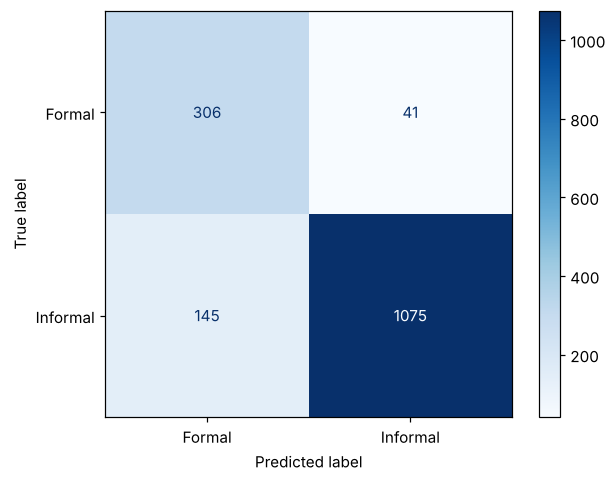

In [4]:
from sklearn.metrics import balanced_accuracy_score, roc_auc_score, ConfusionMatrixDisplay
MEJOR = "Regresión logística (L2)"   # modelo elegido arriba
mejor = Pipeline([("prep", preprocesador()), ("modelo", modelos[MEJOR])]).fit(X_tr, y_tr)
prob = mejor.predict_proba(X_te)[:, 1]
pred = mejor.predict(X_te)
print(f"Test · exactitud balanceada = {balanced_accuracy_score(y_te, pred):.3f} · ROC-AUC = {roc_auc_score(y_te, prob):.3f}")
print(f"       recall informales = {recall_score(y_te, pred):.3f} · recall formales = {recall_score(y_te, pred, pos_label=0):.3f}")
ConfusionMatrixDisplay.from_estimator(mejor, X_te, y_te, display_labels=["Formal", "Informal"], cmap="Blues")
plt.show()